Question1 

In [3]:
# PROJECT 2: CREDIT CARD FRAUD DETECTION
# Statistical outlier baseline using robust Z-scores

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# ------------------------------------------------
#  LOADING THE CREDITCARD DATA
# ------------------------------------------------

df = pd.read_csv("creditcard.csv")

print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())



Dataset shape: (284807, 31)

First five records:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.1412

In [7]:
# ------------------------------------------------
#  EXPLORE DATA
# ------------------------------------------------

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sum())





Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values:
0


Missing values: The dataset contains no missing values. Therefore, there is no need for imputation or deletion of records due to missing data.


In [8]:
print("\nDuplicate rows:")
print(df.duplicated().sum())



Duplicate rows:
1081



Duplicate records: The inspection identified 1,081 duplicate rows beyond their first occurrences. These should be investigated rather than automatically removed. Identical transaction records may represent repeated transactions, but duplicates can also create misleading evaluation results if copies are split between training and testing datasets.



In [6]:
print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nClass percentages:")
print(df["Class"].value_counts(normalize=True) * 100)

print("\nDescriptive statistics:")
print(df[["Time", "Amount"]].describe())

print("\nAmount skewness:")
print(df["Amount"].skew())


Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Descriptive statistics:
                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000

Amount skewness:
16.977724453761006


Outliers: The maximum transaction amount is considerably higher than the median. This indicates extreme values in the amount distribution. However, these values should not automatically be removed because unusual transaction amounts may be important indicators of fraud.

The PCA variables also contain extreme positive and negative values. Such observations may be useful in identifying unusual transaction patterns.

The Amount variable is strongly positively skewed, with a skewness of approximately 16.98. This indicates that most transactions have relatively small values, while a small number have very large amounts.

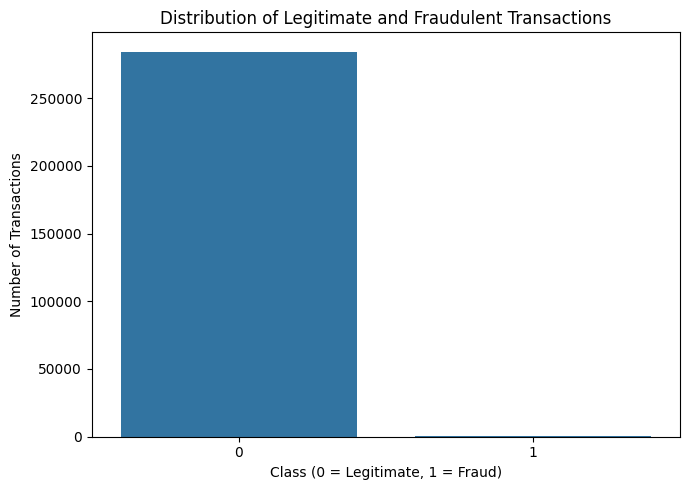

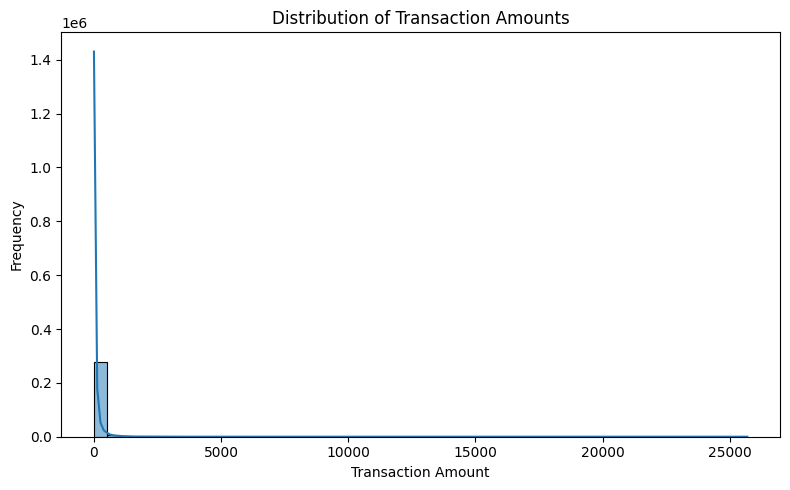

In [9]:
# ------------------------------------------------
#  VISUALISE CLASS IMBALANCE
# ------------------------------------------------

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Class")
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# ------------------------------------------------
#  VISUALISE TRANSACTION AMOUNTS
# ------------------------------------------------

plt.figure(figsize=(8, 5))
sns.histplot(df["Amount"], bins=50, kde=True)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


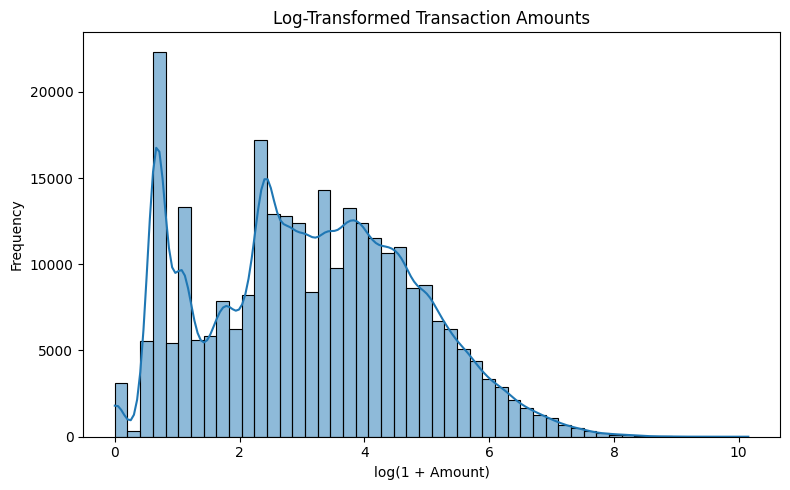

In [10]:
# Log transformation for visualisation
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(df["Amount"]), bins=50, kde=True)
plt.title("Log-Transformed Transaction Amounts")
plt.xlabel("log(1 + Amount)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



In [13]:
# ------------------------------------------------
#  DATA PREPARATION
# ------------------------------------------------

# Separate predictors and target
X = df.drop(columns=["Class"]).copy()
y = df["Class"].astype(int)

# Reduce skewness in Amount
X["Amount"] = np.log1p(X["Amount"])
print("\nAmount skewness:")
print(X["Amount"].skew())


Amount skewness:
0.16270292774164008



Training records: 199393
Testing records: 85414
Training fraud cases: 329
Testing fraud cases: 163

STATISTICAL BASELINE RESULTS
----------------------------
ROC-AUC: 0.9362
Average Precision: 0.0574

TOP-K INVESTIGATION RESULTS
---------------------------
Top 50: Frauds=1, Precision=0.0200, Recall=0.0061
Top 100: Frauds=2, Precision=0.0200, Recall=0.0123
Top 200: Frauds=19, Precision=0.0950, Recall=0.1166
Top 500: Frauds=41, Precision=0.0820, Recall=0.2515


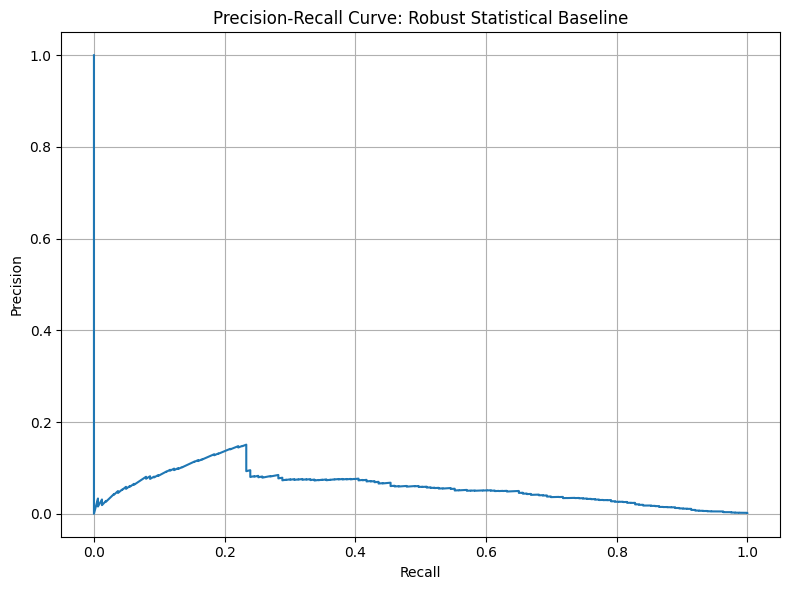

In [14]:

# Identify identical predictor records.
# Copies of identical records are kept in the same split.
groups = pd.util.hash_pandas_object(
    df.drop(columns=["Class"]),
    index=False
).astype("uint64")

# 70% training and 30% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("Training fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())

# ------------------------------------------------
#  FIT ROBUST STATISTICS ON LEGITIMATE TRAINING
#    TRANSACTIONS ONLY
# ------------------------------------------------

X_normal_train = X_train.loc[y_train == 0]

# Median for every predictor
medians = X_normal_train.median()

# Median Absolute Deviation
mad = (X_normal_train - medians).abs().median()

# Robust scale
robust_scale = 1.4826 * mad

# Avoid division by zero
robust_scale = robust_scale.replace(0, np.nan)

# ------------------------------------------------
#  CALCULATE ANOMALY SCORES
# ------------------------------------------------

# Absolute robust Z-scores
robust_z = (
    (X_test - medians).abs() / robust_scale
)

# Replace invalid values
robust_z = robust_z.replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

# Combined anomaly score
anomaly_scores = np.sqrt(
    (robust_z ** 2).mean(axis=1)
)

# ------------------------------------------------
#  EVALUATE RANKING PERFORMANCE
# ------------------------------------------------

roc_auc = roc_auc_score(
    y_test,
    anomaly_scores
)

average_precision = average_precision_score(
    y_test,
    anomaly_scores
)

print("\nSTATISTICAL BASELINE RESULTS")
print("----------------------------")
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(average_precision, 4))

# ------------------------------------------------
#  PRECISION AND RECALL AT INVESTIGATION CAPACITY
# ------------------------------------------------

print("\nTOP-K INVESTIGATION RESULTS")
print("---------------------------")

for k in [50, 100, 200, 500]:

    # Select the k highest anomaly scores
    top_indices = anomaly_scores.nlargest(k).index

    # Count fraud cases in the selected transactions
    true_frauds = y_test.loc[top_indices].sum()

    precision_k = true_frauds / k
    recall_k = true_frauds / y_test.sum()

    print(
        f"Top {k}: "
        f"Frauds={true_frauds}, "
        f"Precision={precision_k:.4f}, "
        f"Recall={recall_k:.4f}"
    )

# ------------------------------------------------
#  PRECISION-RECALL CURVE
# ------------------------------------------------

precision, recall, thresholds = precision_recall_curve(
    y_test,
    anomaly_scores
)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: Robust Statistical Baseline")
plt.grid(True)
plt.tight_layout()
plt.show()

The robust statistical baseline was evaluated using a 70:30 training/testing split. Exact duplicate predictor records were kept within the same partition to reduce the risk of data leakage.
Baseline evaluation results

ROC-AUC: 0.9362
   The ROC-AUC indicates strong ability to rank fraudulent transactions above legitimate transactions. In general, a value closer to 1 indicates better ranking performance. However, ROC-AUC should not be considered in isolation because the dataset contains very few fraudulent transactions.
Average Precision: 0.0574
   The Average Precision score is approximately 5.74%. The fraudulent transaction prevalence in the test set is approximately 0.19%. Therefore, the baseline achieves an average precision roughly 30 times the test-set prevalence. This indicates that the detector identifies useful fraud-related patterns, although its ranking is not sufficiently precise for unrestricted operational use.

Training transactions 199,393
Testing transactions 85,414

The results show that investigating the 500 transactions with the highest anomaly scores would identify 41 of the 163 fraudulent transactions in the test set. This corresponds to a recall of approximately 25.15%.

However, only 8.2% of the top 500 transactions are fraudulent. This means that many transactions flagged by the baseline would still require investigation without ultimately being confirmed as fraud.

The low results for the top 50 and top 100 also show that the detector does not consistently place the most fraudulent transactions at the very top of its ranking

In [15]:

# ------------------------------------------------
#  RANK TRANSACTIONS FOR INVESTIGATION
# ------------------------------------------------

ranked_transactions = X_test.copy()

ranked_transactions["Actual_Class"] = y_test
ranked_transactions["Anomaly_Score"] = anomaly_scores

ranked_transactions = ranked_transactions.sort_values(
    by="Anomaly_Score",
    ascending=False
)

print("\nTop 20 transactions for investigation:")
print(ranked_transactions.head(20))

# Save ranked transactions
ranked_transactions.to_csv(
    "ranked_fraud_transactions.csv",
    index=True
)

print("\nRanked transactions saved successfully.")



Top 20 transactions for investigation:
            Time         V1         V2         V3         V4         V5  \
118764   75207.0  -3.432602  -3.110123   9.382558  -1.218808   7.515238   
58465    48401.0 -36.802320 -63.344698 -20.645794  16.715537 -20.672064   
151296   95286.0 -34.549296 -60.464618 -21.340854  16.875344 -19.229075   
184502  126271.0 -19.618019 -18.539382  -4.310085   6.787660   3.201194   
213188  139145.0 -19.830459 -17.070467  -8.060562   4.425277  -0.533747   
213160  139135.0 -19.438377 -17.164140  -8.610240   4.073813   0.664572   
217409  140878.0 -32.353040 -30.104882 -12.672967   7.870263  -2.380276   
219640  141812.0 -34.614374 -29.145460 -14.985962   7.677798  -8.846632   
261843  160204.0 -26.389030 -17.755687 -10.278766  10.413010  -9.446086   
145090   86624.0 -17.399690 -14.235488  -4.828868   8.461575  -6.041701   
226690  144755.0 -11.066027  -5.312984 -13.391432   2.674077 -27.737487   
233904  147747.0  -3.226248  -4.185371   2.846206   2.190220

The exploration established that the credit card dataset contains 284,807 transactions, 31 columns and no missing values. Only 492 transactions are fraudulent, representing approximately 0.173% of the complete dataset. This severe class imbalance makes conventional accuracy-based evaluation inappropriate.

The amount variable is highly positively skewed, and the dataset contains 1,081 duplicate rows beyond their first occurrences. The preparation process therefore applies a logarithmic transformation to transaction amounts, retains the PCA variables, separates the fraud label from the predictors and uses a grouped training/testing split to reduce duplicate-record leakage.

The robust statistical outlier baseline achieved a ROC-AUC of 0.9362 and Average Precision of 0.0574. When the top 500 transactions were prioritised for investigation, 41 fraudulent transactions were identified, giving a recall of approximately 25.15%.

Overall, the baseline demonstrates useful anomaly-ranking ability but also leaves room for improvement. It should be treated as a benchmark against which more advanced anomaly-detection approaches can be evaluated

Question 2

In [20]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. Load dataset
df = pd.read_csv("creditcard.csv")

X = df.drop(columns=["Class"]).copy()
y = df["Class"].astype(int)

# Transform skewed Amount
X["Amount"] = np.log1p(X["Amount"])

# Keep identical predictor records in the same partition
groups = pd.util.hash_pandas_object(
    df.drop(columns=["Class"]),
    index=False
).astype("uint64")

# 2. Create common 70:30 split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]


# ------------------------------------------------
# APPROACH 1: K-MEANS CLUSTERING
# ------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

kmeans = MiniBatchKMeans(
    n_clusters=2,
    random_state=42,
    batch_size=4096,
    n_init=10,
    max_iter=200
)

# Unsupervised training: do not use y_train
kmeans.fit(X_train_scaled)

# Distance to nearest cluster centroid
cluster_scores = kmeans.transform(
    X_test_scaled
).min(axis=1)


# ------------------------------------------------
# APPROACH 2: CLASSIFICATION
# ------------------------------------------------

classifier = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

# Balance the rare fraud class during training
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

classifier.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

# Predicted fraud probabilities
classification_scores = classifier.predict_proba(
    X_test
)[:, 1]

# ------------------------------------------------
# 3. EVALUATE BOTH MODELS
# ------------------------------------------------

models = {
    "K-Means": cluster_scores,
    "HistGradientBoosting": classification_scores
}

results = []

for model_name, scores in models.items():

    roc = roc_auc_score(y_test, scores)

    ap = average_precision_score(y_test, scores)

    results.append({
        "Model": model_name,
        "ROC-AUC": roc,
        "Average Precision": ap
    })

    print("\n", model_name)
    print("ROC-AUC:", round(roc, 4))
    print("Average Precision:", round(ap, 4))


 K-Means
ROC-AUC: 0.9469
Average Precision: 0.1774

 HistGradientBoosting
ROC-AUC: 0.9693
Average Precision: 0.72


Cluster-based approach
K-Means is justified when the main objective is to discover unusual transaction patterns without depending on historical fraud labels. This is useful when a financial institution has limited labelled fraud data or wants to identify previously unknown transaction patterns. Its main disadvantage is that unusual transactions are not necessarily fraudulent. A legitimate customer may make a transaction that is very different from their usual spending pattern, while a fraudulent transaction may closely resemble normal customer behaviour.

Classification-based approach
HistGradientBoosting is justified when sufficient labelled historical transactions are available. It learns from known fraud cases and can capture complex nonlinear relationships between transaction features.Its main advantage in this experiment is its stronger fraud-ranking performance. It achieved substantially higher Average Precision and identified more fraudulent transactions within each investigation capacity.and its limitation is that it relies on historical fraud patterns. New fraud techniques may not be detected effectively until the model is retrained with suitable examples

In [22]:


   
    # Investigation capacity
for k in [50, 100, 200, 500]:

        top_positions = np.argsort(-scores)[:k]

        fraud_found = y_test.iloc[
            top_positions
        ].sum()

        precision_k = fraud_found / k

        recall_k = fraud_found / y_test.sum()

        print(
            f"Top {k}: "
            f"Fraud found={fraud_found}, "
            f"Precision={precision_k:.4f}, "
            f"Recall={recall_k:.4f}"
        )

# Display comparison table
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df)




Top 50: Fraud found=44, Precision=0.8800, Recall=0.2699
Top 100: Fraud found=86, Precision=0.8600, Recall=0.5276
Top 200: Fraud found=131, Precision=0.6550, Recall=0.8037
Top 500: Fraud found=136, Precision=0.2720, Recall=0.8344

MODEL PERFORMANCE COMPARISON
                  Model   ROC-AUC  Average Precision
0               K-Means  0.946887           0.177416
1  HistGradientBoosting  0.969259           0.719980


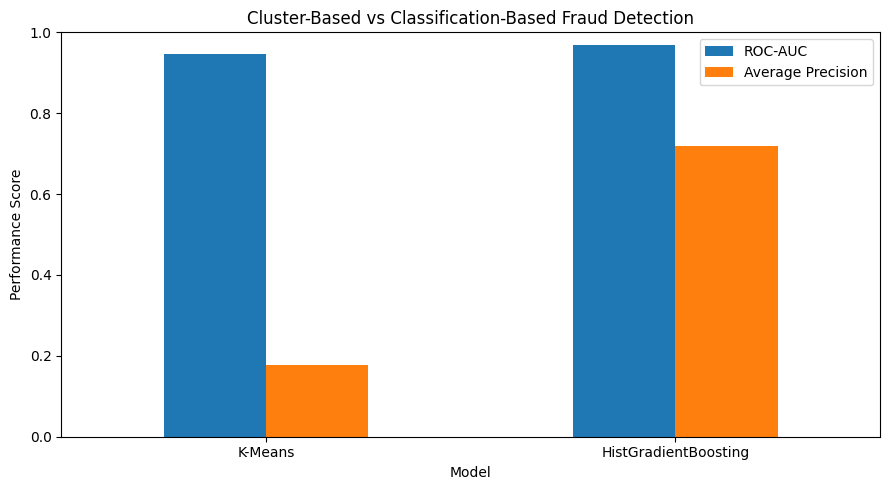

In [23]:
# ------------------------------------------------
# . PLOT ROC-AUC AND AVERAGE PRECISION
# ------------------------------------------------

results_df.set_index("Model")[
    ["ROC-AUC", "Average Precision"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Cluster-Based vs Classification-Based Fraud Detection")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Based on the experimental results, the classification-based approach is the preferred model for this dataset.

The reasons are:
1. It achieved a higher ROC-AUC of 0.9693 compared with 0.9469 for K-Means.
2. Its Average Precision of 0.7200 was substantially higher than the clustering model's 0.1774.
3. It identified 90 fraudulent transactions among the top 100 transactions, compared with 37 for K-Means.
4. It achieved 83.44% recall when investigators examined the top 500 transactions.
However, clustering should not be discarded. It can complement classification by identifying unusual transactions that do not resemble previously labelled fraud cases. A practical fraud detection system could therefore use classification as its primary ranking mechanism and clustering as a supplementary tool for discovering emerging or unfamiliar transaction patterns.

Question 3

In [ ]:
An unusual transaction is not necessarily fraudulent because unusual behaviour does not automatically 
mean criminal activity. In credit card fraud detection, an unusual transaction is one that differs from the 
normal spending patterns of a cardholder or the general transaction population. However, there may be legitimate
reasons for such differences.

A.  Reasons why unusual transactions may be legitimate
    1. Large purchases: A customer may normally spend small amounts but occasionally purchase an expensive household appliance, 
       vehicle part or electronic device. Although the transaction is unusual, it may be genuine.
    2. Travelling: A customer who normally makes transactions in one location may suddenly use their card in another country.
       This may be due to legitimate travel rather than card theft.
    3. Emergency expenses: Medical bills, vehicle repairs or other emergencies may cause a customer to make unusually large or 
       frequent transactions.
    4. Changes in spending behaviour: Customers may change their shopping habits during holidays, celebrations,
       school-opening periods or special occasions.
    5. New merchants: A transaction at a merchant where the customer has never previously shopped may appear unusual but can
       still be legitimate.
    6. Multiple transactions: A customer may make several transactions within a short period when purchasing different items or 
       paying several service providers.

B. Implications for anomaly detection
An anomaly detection algorithm identifies transactions that differ from expected patterns. It does not automatically 
establish whether those transactions are fraudulent.